# Proyecto Final , Detección de *Bacteroides fragilis* División II (cfiA+) por MALDI-TOF MS

**Proyecto:** Detección de cfiA en *B. fragilis* mediante desplazamiento de masa en espectros MALDI-TOF , Hospital Garrahan
**Dataset:** 14 cepas, 28 espectros, PCR confirmada para la totalidad de la cohorte (5 cfiA+, 9 cfiA−)
**Features:** desplazamiento (Da) de los 5 marcadores descriptos por Nagy et al. (2011)
**Clasificador:** Random Forest, validado con Leave-One-Strain-Out cross-validation (LOSO-CV)

## Por qué este enfoque (resumen , ver informe completo para la justificación extendida)

- **Preprocesamiento dirigido, no binning genérico:** un primer intento de binning del espectro completo no separó las clases (ruido de calibración dominante). Siguiendo Nagy et al. (2011), el marcador de cfiA no es un pico que aparece/desaparece sino el mismo pico desplazándose 9–23 Da en 5 coordenadas de masa puntuales , por eso se usan features dirigidas de desplazamiento, no bins genéricos.
- **Random Forest, no una red neuronal profunda:** con n=14 cepas (5 positivas), ninguna arquitectura de las vistas en el curso (CNN, autoencoder, LSTM, Transformer) tiene sustento estadístico, ni la regularización (BatchNorm/Dropout/L2) compensa un volumen de datos tan chico. RF no asume separabilidad lineal, da importancia de variables, y su capacidad se controla con `max_depth`/`min_samples_leaf`.
- **LOSO-CV, no K-fold estándar:** la unidad de independencia biológica es la cepa, no la réplica, dos réplicas de una misma cepa son casi idénticas. Agrupar por cepa evita fuga de información.

## Flujo de trabajo de este notebook

1. Carga de los 4 CSV ya exportados por el pipeline de preprocesamiento (`peak_shift_*`, `inventario_cepas`)
2. Control de calidad de réplicas
3. Construcción de la tabla de features (desplazamiento orientado por marcador)
4. Baseline: regla de voto mayoritario ya utilizada en el proyecto del hospital
5. Grupos para Leave-One-Strain-Out (LOSO)
6. Random Forest con LOSO-CV
7. Consolidación de predicciones por cepa
8. Métricas clínicas (sensibilidad prioritaria)
9. Importancia de marcadores
10. Curva ROC
11. Comparación baseline vs. Random Forest
12. Exportación de resultados a `results/`


## 1. Setup

Semilla fija (`RANDOM_STATE`) en todo lo que tiene aleatoriedad: con n=14 cepas, un Random Forest sin semilla fija da un número distinto en cada corrida, y no se puede reportar como un resultado reproducible.

In [3]:
import numpy as np
import pandas as pd
import os

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score,
    confusion_matrix, roc_curve, auc
)

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 110

COLOR_NAVY = "#1B2A4A"
COLOR_TEAL = "#2A9D8F"
COLOR_AMBER = "#E9C46A"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

REPO = os.getcwd()
if os.path.basename(REPO) == "notebooks":
    REPO = os.path.dirname(REPO)
DATA_DIR = os.path.join(REPO, "data")
RESULTS_DIR = os.path.join(REPO, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Directorio de datos:", DATA_DIR)
print("Directorio de resultados:", RESULTS_DIR)

Directorio de datos: /home/facundo/Documentos/doctorado/curso_DL4BIO/proyecto-final-cfiA-MALDI-FacundoBravo7777/data
Directorio de resultados: /home/facundo/Documentos/doctorado/curso_DL4BIO/proyecto-final-cfiA-MALDI-FacundoBravo7777/results


## 2. Carga de los 4 CSV ya exportados

Estos 4 archivos son la salida del pipeline de preprocesamiento (`cfiA_peak_shift_pipeline`) corrido previamente sobre los archivos `.rep` de SARAMIS (procesados con `mdbtools`). No se vuelve a leer ningún `.rep` acá, se parte directamente del pipeline ya validado, para no duplicar lógica de parseo en dos lugares distintos.

In [4]:
raw = pd.read_csv(os.path.join(DATA_DIR, "peak_shift_results_raw.csv"))
summary_por_cepa = pd.read_csv(os.path.join(DATA_DIR, "peak_shift_summary_por_cepa.csv"))
concordance = pd.read_csv(os.path.join(DATA_DIR, "peak_shift_concordance.csv"))
inventario = pd.read_csv(os.path.join(DATA_DIR, "inventario_cepas.csv"))

raw["strain_id"] = raw["strain_id"].astype(str)
summary_por_cepa["strain_id"] = summary_por_cepa["strain_id"].astype(str)
inventario["strain_id"] = inventario["strain_id"].astype(str)

print(f"Filas en raw (espectro x marcador): {len(raw)}")
print(f"Espectros unicos: {raw['ID_'].nunique()}  |  Cepas: {raw['strain_id'].nunique()}")
print(f"Excluidos por identificacion fallida: {raw[raw['excluido_id_fallida']]['ID_'].nunique()}")
raw.head()

Filas en raw (espectro x marcador): 135
Espectros unicos: 27  |  Cepas: 14
Excluidos por identificacion fallida: 1


,ID_,strain_id,replica,pcr_status,organism,excluido_id_fallida,marker,observed_mass,call
0,aa7cedf3-1aad-44e6-8275-08d96f38302d,5766,1,cfiA_negative,fragilis,False,marker_1,4708.85,cfiA_negativo_like
1,aa7cedf3-1aad-44e6-8275-08d96f38302d,5766,1,cfiA_negative,fragilis,False,marker_2,4814.86,cfiA_negativo_like
2,aa7cedf3-1aad-44e6-8275-08d96f38302d,5766,1,cfiA_negative,fragilis,False,marker_3,5013.91,cfiA_negativo_like
3,aa7cedf3-1aad-44e6-8275-08d96f38302d,5766,1,cfiA_negative,fragilis,False,marker_4,5200.88,cfiA_negativo_like
4,aa7cedf3-1aad-44e6-8275-08d96f38302d,5766,1,cfiA_negative,fragilis,False,marker_5,5285.40,cfiA_positivo_like


## 3. Control de calidad de réplicas

De las 14 cepas confirmadas, 4 tienen alguna limitación de duplicado real (réplica 2 faltante o repetición técnica de la réplica 1 por error de operador en SARAMIS). Esto se declara explícitamente para el informe: no son 14 cepas duplicadas de manera uniforme.

In [5]:
cepas_confirmadas = set(summary_por_cepa["strain_id"])
inv_confirmadas = inventario[inventario["strain_id"].isin(cepas_confirmadas)]
print(inv_confirmadas.to_string(index=False))

problemas = inv_confirmadas[inv_confirmadas["estado"] != "OK"]
print(f"\nCepas con limitacion de duplicado: {problemas['strain_id'].tolist()}")

strain_id  n_rep1  n_rep2                                                          estado
     5766       1       1                                                              OK
     6085       1       1                                                              OK
     6447       2       0 FALTA REP2 real (rep1 adquirida >=2 veces, rep2 nunca generada)
     6655       2       0 FALTA REP2 real (rep1 adquirida >=2 veces, rep2 nunca generada)
     6771       1       1                                                              OK
     6839       1       1                                                              OK
     6862       1       1                                                              OK
     6392       1       1                                                              OK
     6399       1       0                              FALTA REP2 (solo 1 espectro total)
     6717       1       1                                                              OK
     6741 

## 4. Construcción de la tabla de features

Se usa `observed_mass` (la masa real del pico encontrado), no el `call` categórico ya colapsado, así el Random Forest puede aprender del *grado* de desplazamiento, no solo de para qué lado cae. Cada marcador se orienta con signo consistente (`shift_orientado > 0` siempre significa "corrido hacia el fenotipo cfiA+"), y los 5 valores `sin_pico_detectado` se imputan con la mediana del marcador, con un flag binario de faltante.

In [6]:
LITERATURE_MARKERS = {
    'marker_1': {'neg_ref': 4711, 'pos_ref': 4688},
    'marker_2': {'neg_ref': 4817, 'pos_ref': 4826},
    'marker_3': {'neg_ref': 5017, 'pos_ref': 5002},
    'marker_4': {'neg_ref': 5204, 'pos_ref': 5189},
    'marker_5': {'neg_ref': 5268, 'pos_ref': 5282},
}
MARKER_COLS = list(LITERATURE_MARKERS.keys())

valid = raw[~raw["excluido_id_fallida"]].copy()

def shift_orientado(row):
    ref = LITERATURE_MARKERS[row["marker"]]
    signo = 1 if ref["pos_ref"] > ref["neg_ref"] else -1
    if pd.isna(row["observed_mass"]):
        return np.nan
    return (row["observed_mass"] - ref["neg_ref"]) * signo

valid["shift"] = valid.apply(shift_orientado, axis=1)

features = valid.pivot_table(
    index=["strain_id", "replica", "pcr_status"],
    columns="marker", values="shift"
).reset_index()
features = features[["strain_id", "replica", "pcr_status"] + MARKER_COLS]

for m in MARKER_COLS:
    faltantes = features[m].isna()
    if faltantes.any():
        mediana = features[m].median()
        features[f"{m}_missing"] = faltantes.astype(int)
        features[m] = features[m].fillna(mediana)
        print(f"{m}: {faltantes.sum()} valores imputados con mediana={mediana:.2f}")

features["y"] = (features["pcr_status"] == "cfiA_positive").astype(int)

print(f"\nTabla de features: {len(features)} replicas, {features['strain_id'].nunique()} cepas")
features

marker_3: 5 valores imputados con mediana=2.40

Tabla de features: 26 replicas, 14 cepas


marker,strain_id,replica,pcr_status,marker_1,marker_2,marker_3,marker_4,marker_5,marker_3_missing,y
0,5766,1,cfiA_negative,2.15,-2.14,3.09,3.12,17.40,0,0
1,5766,2,cfiA_negative,1.48,-2.48,2.40,3.12,18.81,1,0
2,6085,1,cfiA_positive,26.02,7.46,16.65,17.59,10.60,0,1
3,6085,2,cfiA_positive,25.36,8.14,16.65,18.29,20.50,0,1
4,6392,1,cfiA_positive,25.36,7.46,16.65,17.59,21.21,0,1
5,6392,2,cfiA_positive,24.69,8.81,14.59,16.19,21.92,0,1
6,6399,1,cfiA_positive,25.47,7.31,16.85,17.14,20.23,0,1
7,6447,1,cfiA_positive,25.36,8.14,15.97,2.17,12.02,0,1
8,6447,1b,cfiA_positive,26.02,6.79,15.97,3.57,19.09,0,1
9,6655,1,cfiA_positive,25.36,8.14,-4.00,16.19,21.21,0,1


## 5. Baseline: voto mayoritario ya consolidado

Reproduce el criterio ya usado en el proyecto del hospital, cepa predicha positiva si al menos 3 de los 5 marcadores dan `cfiA_positivo_like` , sobre el mismo set de 14 cepas que se le compara al Random Forest.

In [7]:
marker_call_cols = [c for c in summary_por_cepa.columns if c.startswith("marker_")]

def voto_mayoritario(row):
    votos_pos = sum(row[c] == "cfiA_positivo_like" for c in marker_call_cols)
    return int(votos_pos >= 3)

baseline = summary_por_cepa.copy()
baseline["y_true"] = (baseline["pcr_status"] == "cfiA_positive").astype(int)
baseline["baseline_pred"] = baseline.apply(voto_mayoritario, axis=1)

acc_base = accuracy_score(baseline["y_true"], baseline["baseline_pred"])
sens_base = recall_score(baseline["y_true"], baseline["baseline_pred"])
spec_base = recall_score(baseline["y_true"], baseline["baseline_pred"], pos_label=0)

print(f"Baseline (voto mayoritario, n={len(baseline)} cepas):")
print(f"  Accuracy:      {acc_base:.3f}")
print(f"  Sensibilidad:  {sens_base:.3f}")
print(f"  Especificidad: {spec_base:.3f}")
baseline[["strain_id", "pcr_status"] + marker_call_cols + ["baseline_pred"]]

Baseline (voto mayoritario, n=14 cepas):
  Accuracy:      1.000
  Sensibilidad:  1.000
  Especificidad: 1.000


,strain_id,pcr_status,marker_1,marker_2,marker_3,marker_4,marker_5,baseline_pred
0,5766,cfiA_negative,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_positivo_like,0
1,6085,cfiA_positive,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,1
2,6392,cfiA_positive,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,1
3,6399,cfiA_positive,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,1
4,6447,cfiA_positive,cfiA_positivo_like,cfiA_positivo_like,cfiA_positivo_like,cfiA_negativo_like,cfiA_positivo_like,1
5,6655,cfiA_positive,cfiA_positivo_like,cfiA_positivo_like,cfiA_negativo_like,cfiA_positivo_like,cfiA_positivo_like,1
6,6717,cfiA_negative,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,0
7,6741,cfiA_negative,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,0
8,6771,cfiA_negative,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,0
9,6839,cfiA_negative,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,cfiA_negativo_like,0


## 6. Grupos para Leave-One-Strain-Out (LOSO)

La decisión metodológica central: el grupo de validación cruzada es la **cepa**, no la réplica. Con 14 cepas, `LeaveOneGroupOut` da 14 folds.

In [8]:
X = features[MARKER_COLS + [c for c in features.columns if c.endswith("_missing")]].values
y = features["y"].values
groups = features["strain_id"].values

logo = LeaveOneGroupOut()
print(f"LOSO-CV: {logo.get_n_splits(groups=groups)} folds (uno por cepa)")

LOSO-CV: 14 folds (uno por cepa)


## 7. Random Forest con LOSO-CV

Hiperparámetros elegidos para controlar la capacidad del modelo dado el tamaño de muestra: `max_depth=3` y `min_samples_leaf=2` evitan que los árboles memoricen ruido con ~24 réplicas de entrenamiento por fold; `class_weight="balanced"` compensa el desbalance 9 negativas / 5 positivas; `random_state` fijo para reproducibilidad.

In [9]:
resultados = []

for train_idx, test_idx in logo.split(X, y, groups=groups):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    strain_out = groups[test_idx][0]

    clf = RandomForestClassifier(
        n_estimators=200, max_depth=3, min_samples_leaf=2,
        class_weight="balanced", random_state=RANDOM_STATE,
    )
    clf.fit(X_train, y_train)

    proba = clf.predict_proba(X_test)[:, 1]
    pred = clf.predict(X_test)

    for i, idx in enumerate(test_idx):
        resultados.append({
            "strain_id": strain_out,
            "replica": features.iloc[idx]["replica"],
            "y_true": y_test[i],
            "rf_pred": pred[i],
            "rf_proba": proba[i],
        })

rf_out = pd.DataFrame(resultados)
rf_out

,strain_id,replica,y_true,rf_pred,rf_proba
0,5766,1,0,0,0.066167
1,5766,2,0,0,0.048000
2,6085,1,1,1,0.952500
3,6085,2,1,1,0.998750
4,6392,1,1,1,0.993167
5,6392,2,1,1,0.983167
6,6399,1,1,1,0.998333
7,6447,1,1,1,0.693333
8,6447,1b,1,1,0.702917
9,6655,1,1,1,0.758036


## 8. Consolidación de predicciones por cepa

Se consolida por **promedio de probabilidad** entre réplicas, no por voto binario, evitando reglas de desempate arbitrarias cuando el RF pudiera dar predicciones distintas en cada réplica.

In [10]:
por_cepa = rf_out.groupby("strain_id").agg(
    y_true=("y_true", "first"),
    n_replicas=("rf_pred", "size"),
    proba_promedio=("rf_proba", "mean"),
).reset_index()

por_cepa["rf_pred_cepa"] = (por_cepa["proba_promedio"] >= 0.5).astype(int)
por_cepa.sort_values("proba_promedio")

,strain_id,y_true,n_replicas,proba_promedio,rf_pred_cepa
13,7681,0,2,0.005804,0
12,7648,0,1,0.006250,0
8,6771,0,2,0.019921,0
11,6862,0,2,0.035667,0
6,6717,0,2,0.047292,0
9,6839,0,2,0.050097,0
0,5766,0,2,0.057083,0
7,6741,0,2,0.060625,0
10,6843,0,2,0.085250,0
4,6447,1,2,0.698125,1


## 9. Métricas clínicas

La sensibilidad pesa más que la accuracy acá: un falso negativo (cepa cfiA+ clasificada como negativa) es el escenario que el proyecto busca evitar, mientras que un falso positivo solo deriva en confirmar por PCR.

In [11]:
y_true_cepa = por_cepa["y_true"]
y_pred_cepa = por_cepa["rf_pred_cepa"]

acc = accuracy_score(y_true_cepa, y_pred_cepa)
sens = recall_score(y_true_cepa, y_pred_cepa)
spec = recall_score(y_true_cepa, y_pred_cepa, pos_label=0)
prec = precision_score(y_true_cepa, y_pred_cepa, zero_division=0)

print(f"Random Forest (LOSO-CV, consolidado por cepa, n={len(por_cepa)} cepas):")
print(f"  Accuracy:      {acc:.3f}")
print(f"  Sensibilidad:  {sens:.3f}")
print(f"  Especificidad: {spec:.3f}")
print(f"  Precision:     {prec:.3f}")
print()
print("Matriz de confusion (filas=real, columnas=predicho; 0=neg, 1=pos):")
print(confusion_matrix(y_true_cepa, y_pred_cepa))

Random Forest (LOSO-CV, consolidado por cepa, n=14 cepas):
  Accuracy:      1.000
  Sensibilidad:  1.000
  Especificidad: 1.000
  Precision:     1.000

Matriz de confusion (filas=real, columnas=predicho; 0=neg, 1=pos):
[[9 0]
 [0 5]]


## 10. Importancia de marcadores

Entrenado con todos los datos (no con los 14 modelos transitorios del LOSO-CV), es solo para interpretación, no para volver a predecir con este modelo puntual.

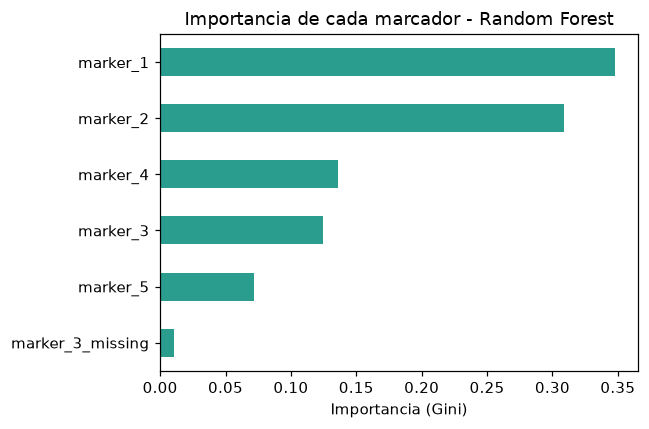

marker_1            0.348018
marker_2            0.309037
marker_4            0.135758
marker_3            0.124775
marker_5            0.071566
marker_3_missing    0.010845
dtype: float64

In [12]:
clf_final = RandomForestClassifier(
    n_estimators=200, max_depth=3, min_samples_leaf=2,
    class_weight="balanced", random_state=RANDOM_STATE,
)
clf_final.fit(X, y)

feature_names = MARKER_COLS + [c for c in features.columns if c.endswith("_missing")]
importancias = pd.Series(clf_final.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 4))
importancias.plot(kind="barh", ax=ax, color=COLOR_TEAL)
ax.set_xlabel("Importancia (Gini)")
ax.set_title("Importancia de cada marcador - Random Forest")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "importancia_marcadores.png"), dpi=150)
plt.show()

importancias

## 11. Curva ROC

Con 9 negativas y 5 positivas confirmadas por PCR, esta curva sí tiene sustento real. Se usan las probabilidades **out-of-fold** del LOSO-CV (no las del modelo final entrenado con todo), para que refleje capacidad de generalización real. Con n=14 cepas, cualquier AUC tiene un intervalo de confianza amplio, se reporta como orientativo, no como resultado cerrado.

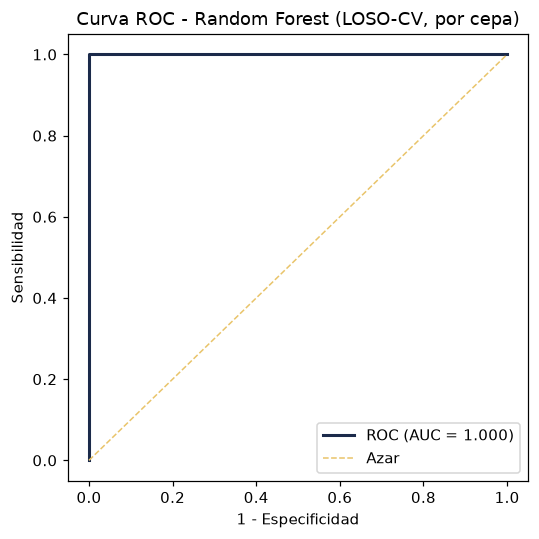

AUC: 1.000
Con n=14 cepas, tratar el AUC como orientativo, no como resultado definitivo.


In [13]:
fpr, tpr, thresholds = roc_curve(y_true_cepa, por_cepa["proba_promedio"])
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color=COLOR_NAVY, lw=2, label=f"ROC (AUC = {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], color=COLOR_AMBER, lw=1, linestyle="--", label="Azar")
ax.set_xlabel("1 - Especificidad")
ax.set_ylabel("Sensibilidad")
ax.set_title("Curva ROC - Random Forest (LOSO-CV, por cepa)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "curva_roc.png"), dpi=150)
plt.show()

print(f"AUC: {roc_auc:.3f}")
print("Con n=14 cepas, tratar el AUC como orientativo, no como resultado definitivo.")

## 12. Comparación final: baseline vs. Random Forest

Mismo set de 14 cepas para ambos métodos, para que la comparación sea válida.

In [14]:
comparacion = pd.DataFrame({
    "Metodo": ["Voto mayoritario (baseline)", "Random Forest (LOSO-CV)"],
    "Accuracy": [acc_base, acc],
    "Sensibilidad": [sens_base, sens],
    "Especificidad": [spec_base, spec],
})
comparacion

,Metodo,Accuracy,Sensibilidad,Especificidad
0,Voto mayoritario (baseline),1.0,1.0,1.0
1,Random Forest (LOSO-CV),1.0,1.0,1.0


## 13. Exportación de resultados

Se guardan las predicciones por cepa, la importancia de features, la tabla comparativa y las figuras, insumos para la sección de resultados del informe.

In [15]:
por_cepa.to_csv(os.path.join(RESULTS_DIR, "resultados_rf_por_cepa.csv"), index=False)
importancias.to_csv(os.path.join(RESULTS_DIR, "importancia_marcadores.csv"), header=["importancia"])
comparacion.to_csv(os.path.join(RESULTS_DIR, "comparacion_baseline_vs_rf.csv"), index=False)

print("Exportado en results/:")
print(" - resultados_rf_por_cepa.csv")
print(" - importancia_marcadores.csv")
print(" - comparacion_baseline_vs_rf.csv")
print(" - importancia_marcadores.png")
print(" - curva_roc.png")

Exportado en results/:
 - resultados_rf_por_cepa.csv
 - importancia_marcadores.csv
 - comparacion_baseline_vs_rf.csv
 - importancia_marcadores.png
 - curva_roc.png


## Limitaciones a declarar explícitamente en el informe

- n=14 cepas (5 positivas, 9 negativas) es chico incluso para un Random Forest acotado; cualquier métrica reportada tiene un intervalo de confianza ancho (IC 95% Wilson: sensibilidad 56,6–100%, especificidad 70,1–100%), es prueba de concepto formalizada, no un resultado cerrado.
- No todas las cepas tienen duplicado real: 6399 y 7648 quedaron con 1 solo espectro válido; 6447 y 6655 tienen 2 espectros pero ambos son repeticiones técnicas de la réplica 1 (error de operador), no un duplicado biológico independiente.
- Los 5 valores `sin_pico_detectado` (todos en marker_3) se imputaron por mediana con flag de faltante, no son mediciones reales.
- Esta validación es interna (LOSO dentro del mismo set de 14 cepas). No reemplaza una validación con cepas completamente nuevas, no vistas en ningún fold.
- El AUC y el umbral dependen del balance 5 positivas / 9 negativas de este set puntual,  no extrapolar a un set con balance de clases distinto sin recalibrar.
